# BÀI THỰC HÀNH LAB 2 — MODULE CV05: MÔ HÌNH MÙA VỤ SARIMA(p,d,q)(P,D,Q)[12] & ĐỐI CHUẨN BENCHMARK

> **Học phần:** Phân tích dữ liệu chuỗi thời gian và dự báo — Khoa CNTT, Trường ĐH Giao thông Vận tải TP.HCM (UTH)  
> **Giảng viên hướng dẫn:** PhD. Nguyễn Thị Khánh Tiên (`tienntk@ut.edu.vn`)  
> **Nhóm thực hiện:** Nhóm 7 — **Phụ trách CV05:** Bùi Trần Ngọc Khải  
> **Bộ dữ liệu:** `a10.csv` (Doanh số bán thuốc chống tiểu đường theo tháng tại Úc, 204 tháng: `07/1991 – 06/2008`)  

---

### Ràng buộc kỹ thuật bắt buộc (Pipeline Golden Rules)
1. **Không rò rỉ dữ liệu (Zero Lookahead Bias):** Chỉ ước lượng tham số và lựa chọn mô hình trên `train.csv` (`163` tháng: `07/1991 – 01/2005`).
2. **Cấu trúc mùa vụ bắt buộc:** Chu kỳ năm $s = 12$ tháng, bậc sai phân mùa vụ $D = 1$ kết hợp sai phân thường $d = 1$.
3. **Chẩn đoán phần dư nghiêm ngặt:** Phần dư phải đạt chuẩn **White Noise** tại các độ trễ mùa vụ `lag 12` và `lag 24` ($p\text{-value} > 0.05$ qua kiểm định Ljung–Box).
4. **Dự báo ngoài mẫu độc lập:** Dự báo một mạch `41` tháng tập `test.csv` (`02/2005 – 06/2008`) không cập nhật trọng số, đối chuẩn trực diện với `ARIMA(1, 1, 1)` từ CV04.

## 0. Khởi tạo môi trường & nạp module chuẩn hóa `cv05_sarima_model`

In [1]:
import os, sys, pickle, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from statsmodels.tsa.stattools import adfuller

# Thiết lập đường dẫn chuẩn tương thích khi chạy từ thư mục notebooks/ hoặc gốc lab
CWD = os.getcwd()
ROOT = os.path.abspath(os.path.join(CWD, '..')) if os.path.basename(CWD) == 'notebooks' else os.path.abspath(CWD)
SRC_DIR = os.path.join(ROOT, 'src')
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from cv05_sarima_model import (
    TRAIN_CSV, TEST_CSV, ARIMA_METRICS, FIG_DIR, TABLE_DIR, MODEL_DIR,
    load_data, evaluate_sarima_candidates, fit_sarima,
    diagnose_residuals_sarima, forecast_test, save_forecast_details,
    compute_metrics, build_benchmark_table,
    plot_sarima_forecast, plot_model_comparison
)
print('Project Root:', ROOT)

Project Root: e:\Chuỗi_TG\time-series-lab2


## 1. Nạp tập Train / Test & Kiểm chứng tính dừng mùa vụ ($d=1, D=1, s=12$)
Kiểm tra đối chứng nghiệm đơn vị ADF trên chuỗi gốc, sai phân thường $\Delta y_t$, sai phân mùa vụ $\Delta_{12} y_t$ và sai phân kép $\Delta \Delta_{12} y_t$ trên tập Train.

In [2]:
train, test = load_data(TRAIN_CSV, TEST_CSV)
print(f'Tập Train : {len(train)} tháng ({train.index.min():%Y-%m} -> {train.index.max():%Y-%m})')
print(f'Tập Test  : {len(test)} tháng ({test.index.min():%Y-%m} -> {test.index.max():%Y-%m})')

adf_checks = []
for name, s in [
    ('Chuỗi Train gốc y_t', train),
    ('Sai phân thường d=1: (1-B)y_t', train.diff(1).dropna()),
    ('Sai phân mùa vụ D=1: (1-B^12)y_t', train.diff(12).dropna()),
    ('Sai phân kép d=1, D=1: (1-B)(1-B^12)y_t', train.diff(1).diff(12).dropna()),
]:
    stat, pval, lags, nobs, _, _ = adfuller(s, autolag='AIC')
    adf_checks.append({
        'Biến đổi': name,
        'Số quan sát': nobs,
        'ADF Statistic': round(stat, 4),
        'p-value': f'{pval:.4e}',
        'Kết luận (alpha=0.05)': 'Dừng ✓' if pval < 0.05 else 'Không dừng ✗'
    })
display(pd.DataFrame(adf_checks))

Tập Train : 163 tháng (1991-07 -> 2005-01)
Tập Test  : 41 tháng (2005-02 -> 2008-06)


,Biến đổi,Số quan sát,ADF Statistic,p-value,Kết luận (alpha=0.05)
0,Chuỗi Train gốc y_t,148,2.2309,9.9891e-01,Không dừng ✗
1,Sai phân thường d=1: (1-B)y_t,148,-1.7061,4.2799e-01,Không dừng ✗
2,Sai phân mùa vụ D=1: (1-B^12)y_t,145,-0.1861,9.4016e-01,Không dừng ✗
3,"Sai phân kép d=1, D=1: (1-B)(1-B^12)y_t",145,-8.7879,2.2826e-14,Dừng ✓


## 2. Sàng lọc ứng viên $\text{SARIMA}(p, 1, q)(P, 1, Q)_{12}$ trên tập Train
Tất cả ứng viên được ước lượng độc lập trên `train` (163 tháng), kiểm tra hội tụ, kiểm định White Noise tại lag 12 & 24 và xếp hạng theo AIC/BIC.

In [3]:
cand_df = evaluate_sarima_candidates(train)
display(cand_df[['Model', 'converged', 'AIC', 'BIC', 'LB_pvalue_lag12', 'LB_pvalue_lag24', 'White_Noise_Seasonal', 'Selected', 'Ghi_chu']])

,Model,converged,AIC,BIC,LB_pvalue_lag12,LB_pvalue_lag24,White_Noise_Seasonal,Selected,Ghi_chu
0,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",True,229.454073,241.104693,0.180554,0.584235,True,True,"Ứng viên chính từ ARIMA(1,1,1) + SMA(1)_12"
1,"SARIMA(2, 1, 1)x(0, 1, 1, 12)",True,229.459798,244.023072,0.565878,0.926575,True,False,"Ứng viên từ ARIMA(2,1,1) + SMA(1)_12"
2,"SARIMA(1, 1, 1)x(1, 1, 1, 12)",True,231.109370,245.672644,0.114357,0.490729,True,False,Thêm thành phần tự hồi quy mùa vụ SAR(1)_12
3,"SARIMA(2, 1, 1)x(1, 1, 1, 12)",True,231.247023,248.722953,0.466406,0.889693,True,False,Mở rộng đồng thời AR(2) và SAR(1)_12
4,"SARIMA(1, 1, 1)x(1, 1, 0, 12)",True,233.837930,245.517854,0.115521,0.328872,True,False,Chỉ dùng tự hồi quy mùa vụ SAR(1)_12
5,"SARIMA(0, 1, 1)x(0, 1, 1, 12)",True,233.851680,242.589645,0.028870,0.171608,False,False,Mô hình Airline cổ điển của Box-Jenkins


## 3. Huấn luyện mô hình tối ưu $\text{SARIMA}(1, 1, 1)(0, 1, 1)_{12}$
Mô hình `SARIMA(1, 1, 1)x(0, 1, 1, 12)` đạt đồng thời **AIC thấp nhất (`229.45`)** và **BIC thấp nhất (`241.10`)** trong nhóm thỏa điều kiện nhiễu trắng mùa vụ.

In [4]:
ORDER = (1, 1, 1)
SEASONAL_ORDER = (0, 1, 1, 12)
model_name = f'SARIMA{ORDER}x{SEASONAL_ORDER}'

result = fit_sarima(train, order=ORDER, seasonal_order=SEASONAL_ORDER)
train_time_sec = getattr(result, '_cv05_train_time_sec', np.nan)
print(f'\n[OK] {model_name} | AIC = {result.aic:.4f} | BIC = {result.bic:.4f} | Train Time = {train_time_sec:.4f}s')

                                     SARIMAX Results                                      
Dep. Variable:                              value   No. Observations:                  163
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -110.727
Date:                            Mon, 16 Nov 2026   AIC                            229.454
Time:                                    18:56:48   BIC                            241.105
Sample:                                07-01-1991   HQIC                           234.189
                                     - 01-01-2005                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2710      0.092     -2.955      0.003      -0.451      -0.091
ma.L1         -0.6380      0.076   

## 4. Chẩn đoán nghiêm ngặt phần dư mùa vụ (Seasonal Residual Diagnostics)
Kiểm định Ljung–Box tại các độ trễ `10, 12, 24` và kiểm định chuẩn Jarque–Bera, xác nhận triệt tiêu hoàn toàn các gai nhọn chu kỳ 12 tháng còn sót ở mô hình ARIMA tiêu chuẩn.

,model,lag,ljungbox_stat_raw,ljungbox_pvalue_raw,ljungbox_stat_post_burnin,ljungbox_pvalue_post_burnin,burn_in_excluded,model_df,mean_residual,std_residual,jarque_bera_stat,jarque_bera_pvalue,alpha,white_noise_pass
0,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",10,15.886213,0.102936,12.358851,0.089358,13,3,0.058664,0.530293,2.496017,0.287076,0.05,True
1,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",12,16.238524,0.180554,13.194436,0.154004,13,3,0.058664,0.530293,2.496017,0.287076,0.05,True
2,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",24,21.916768,0.584235,24.101583,0.288163,13,3,0.058664,0.530293,2.496017,0.287076,0.05,True


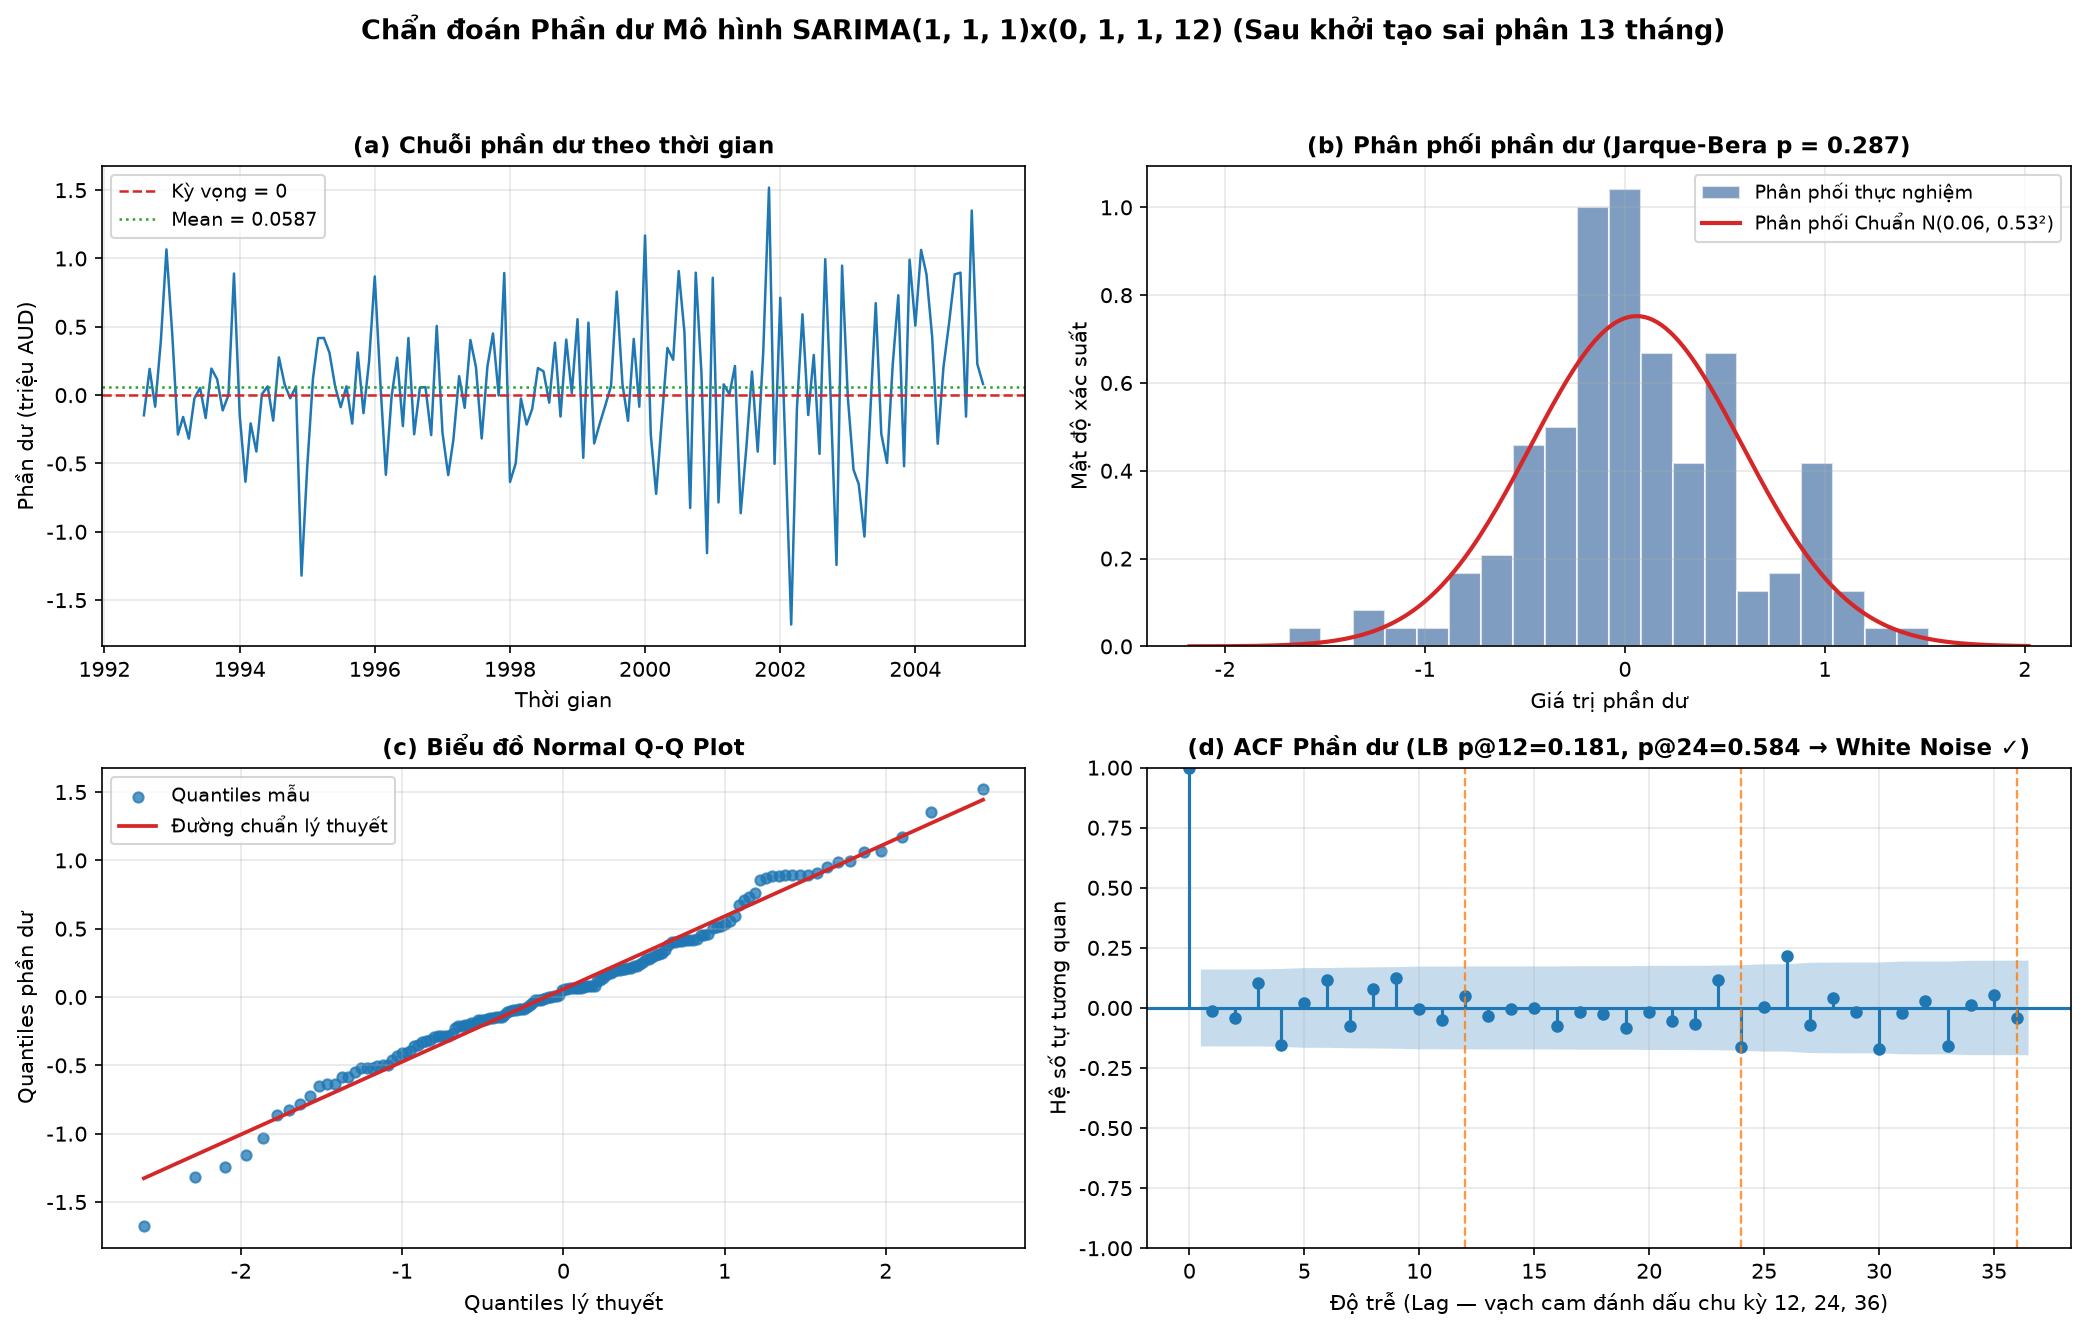

In [5]:
diag = diagnose_residuals_sarima(result, model_label=model_name)
resid_stats_df = pd.read_csv(os.path.join(TABLE_DIR, 'cv05_residual_stats.csv'))
display(resid_stats_df)
display(Image(filename=os.path.join(FIG_DIR, 'cv05_sarima_residual_diag.png')))

## 5. Dự báo ngoài mẫu 41 tháng (Out-of-Sample Forecast) & Phân tích đỉnh/đáy

In [6]:
sarima_fc = forecast_test(result, steps=len(test))
sarima_fc.index = test.index
fc_details = save_forecast_details(result, test)
conf_int_df = result.get_forecast(steps=len(test)).conf_int(alpha=0.05)

metrics = compute_metrics(
    test, sarima_fc, aic=result.aic, bic=result.bic,
    model_name=model_name, train_time_sec=train_time_sec, diag=diag
)
pd.DataFrame([metrics]).to_csv(os.path.join(TABLE_DIR, 'cv05_sarima_metrics.csv'), index=False)
with open(os.path.join(MODEL_DIR, 'sarima_model.pkl'), 'wb') as f:
    pickle.dump(result, f)

print(f"SARIMA Out-of-Sample Metrics -> MAE: {metrics['MAE']:.4f} | RMSE: {metrics['RMSE']:.4f} | MAPE: {metrics['MAPE']:.4f}%")
print('\nTop 5 tháng có sai số tuyệt đối lớn nhất trên tập Test:')
display(fc_details.sort_values('absolute_error', ascending=False).head(5))

SARIMA Out-of-Sample Metrics -> MAE: 1.4727 | RMSE: 1.9107 | MAPE: 8.4818%

Top 5 tháng có sai số tuyệt đối lớn nhất trên tập Test:


,date,actual,predicted,lower_95,upper_95,error,absolute_error,ape_pct
12,2006-02-01,12.536987,16.502395,14.718671,18.286119,-3.965408,3.965408,31.629672
19,2006-09-01,16.623343,20.481944,18.262316,22.701571,-3.858601,3.858601,23.211941
37,2008-03-01,18.264945,21.954694,17.980409,25.928979,-3.689749,3.689749,20.201259
40,2008-06-01,19.431740,22.983493,18.690032,27.276953,-3.551753,3.551753,18.278099
14,2006-04-01,14.233539,17.514478,15.611174,19.417783,-3.280939,3.280939,23.050764


## 6. Bảng đối chuẩn Benchmark & Trực quan hóa `ARIMA(1,1,1)` vs `SARIMA(1,1,1)(0,1,1)[12]`

[INFO] Chưa thấy cv04_arima_metrics.csv trên nhánh hiện tại; nạp số liệu bàn giao chính thức từ CV04 (ARIMA(1, 1, 1) — nhánh hoang-lab02).


,Model,AIC,BIC,Train_Time_s,MAE,RMSE,MAPE,LB_pvalue_lag12,LB_pvalue_lag24,White_Noise,Nhận xét
0,"ARIMA(1, 1, 1)",582.4674,591.7301,0.5313,3.6667,4.6242,18.0386,3.059483e-24,1.520818e-38,False,"Baseline phi mùa vụ: hội tụ phẳng (~17.54), bỏ..."
1,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",229.4541,241.1047,0.2126,1.4727,1.9107,8.4818,1.806000e-01,5.842000e-01,True,Mô hình tối ưu: triệt tiêu tự tương quan mùa v...


[INFO] Chưa thấy cv04_arima_metrics.csv trên nhánh hiện tại; nạp số liệu bàn giao chính thức từ CV04 (ARIMA(1, 1, 1) — nhánh hoang-lab02).


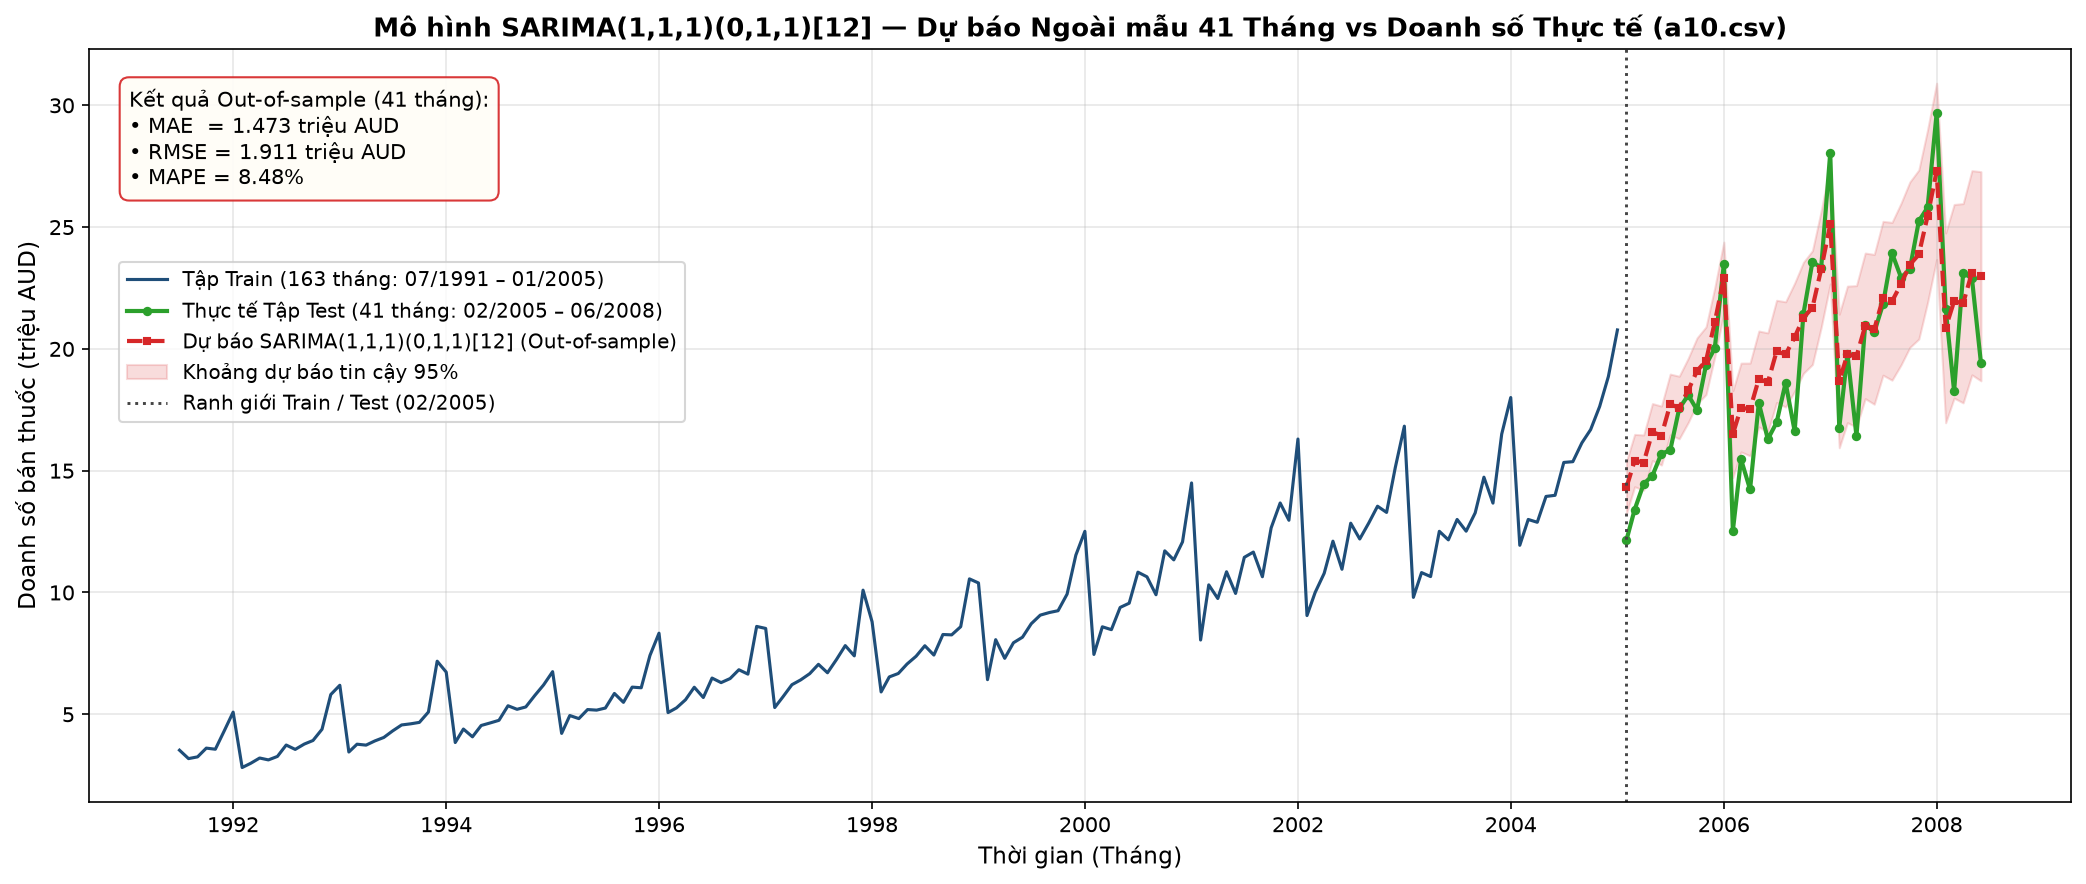

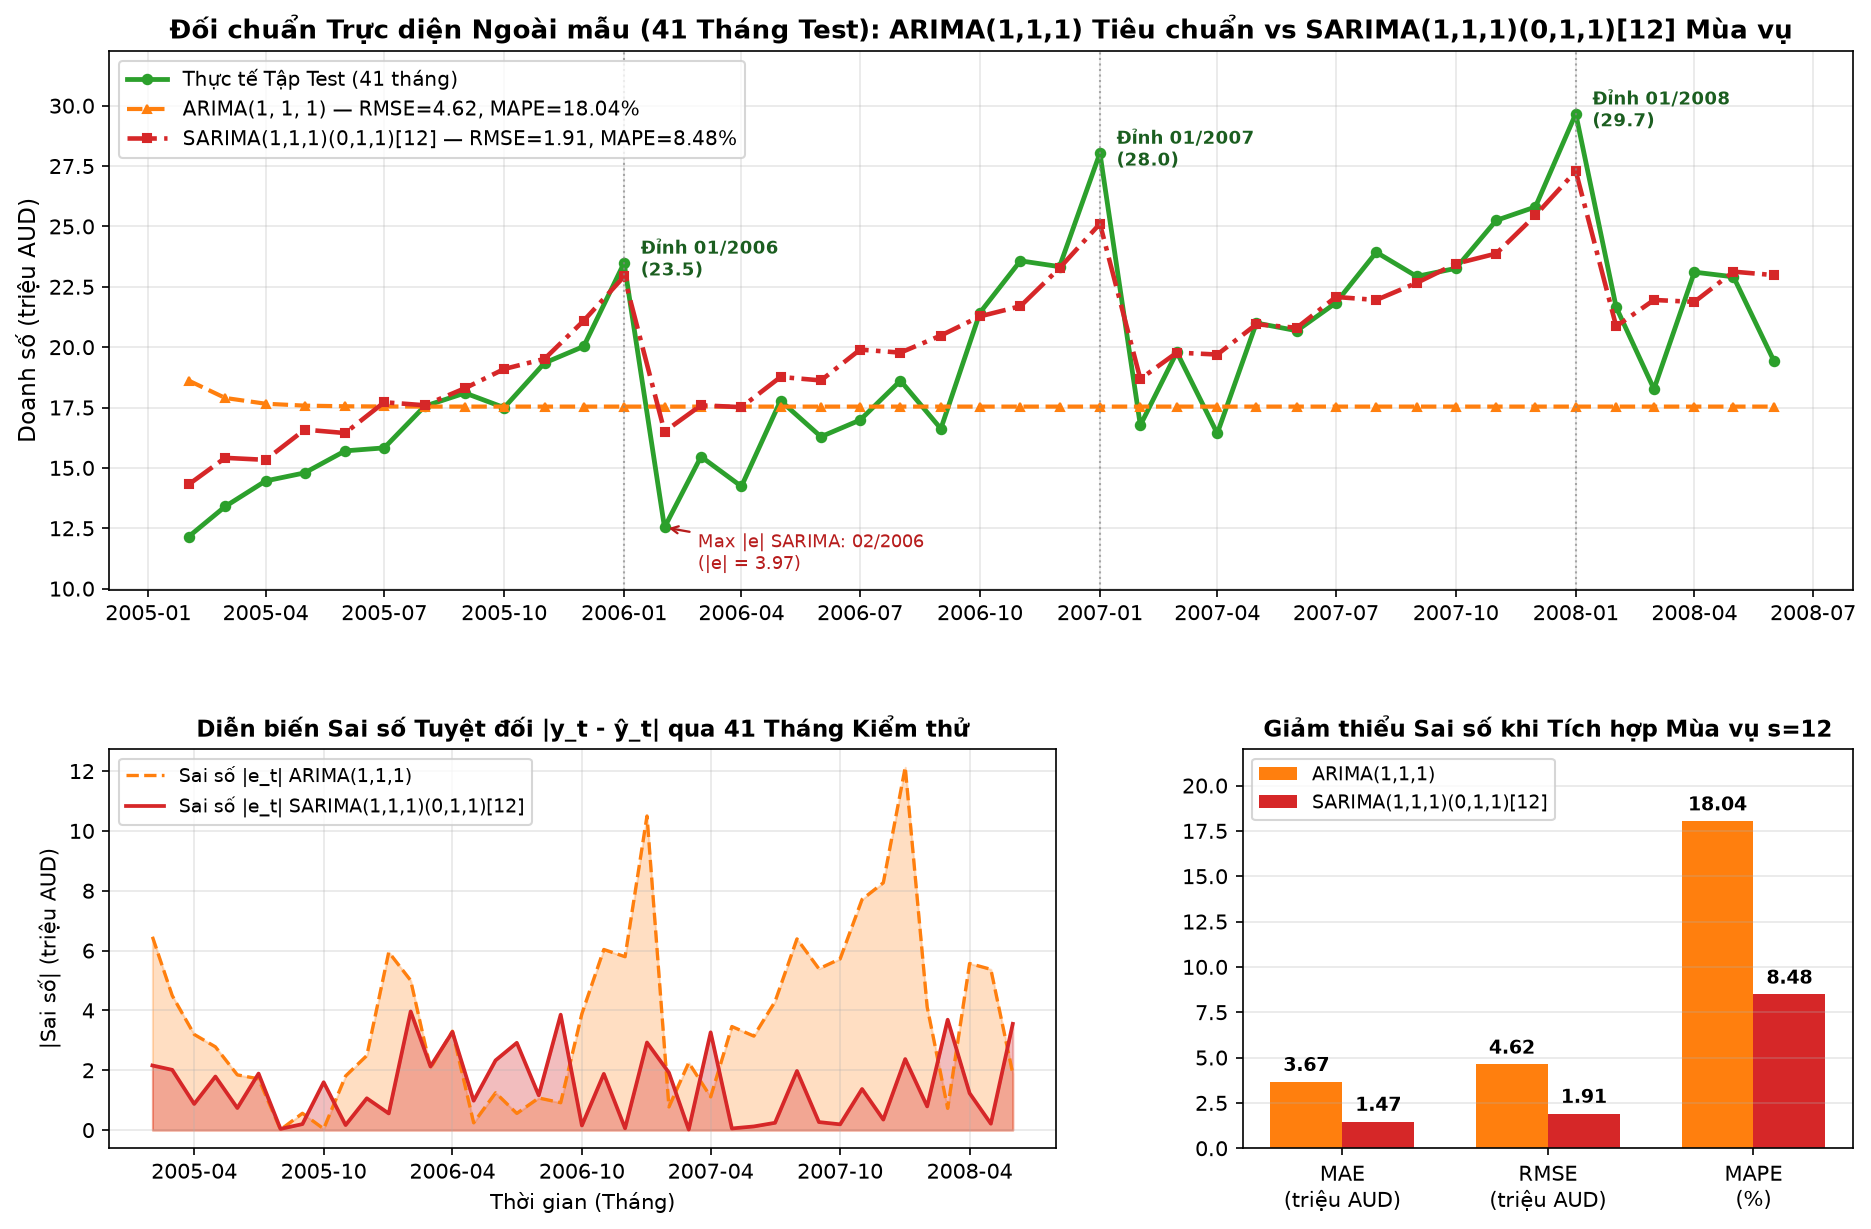

In [7]:
benchmark_df = build_benchmark_table(ARIMA_METRICS, metrics)
display(benchmark_df)

plot_sarima_forecast(train, test, sarima_fc, conf_int=conf_int_df)
plot_model_comparison(test, ARIMA_METRICS, sarima_fc)

display(Image(filename=os.path.join(FIG_DIR, 'cv05_sarima_forecast_vs_actual.png')))
display(Image(filename=os.path.join(FIG_DIR, 'cv05_arima_vs_sarima_comparison.png')))

## 7. Giải đáp Bài 5 — Câu hỏi lý luận chuyên sâu (Câu 6 – Câu 9)

### Câu 6: Đường dự báo có bám sát được xu hướng và chu kỳ dao động thực tế không?
- **ARIMA(1,1,1) tiêu chuẩn:** **Không.** Do thiếu thành phần sai phân mùa vụ $(1-B^{12})$ và hằng số trôi, đường dự báo ngoài mẫu hội tụ nhanh về đường phẳng ngang $\approx 17.54\text{ triệu AUD}$ chỉ sau vài tháng, bỏ lỡ hoàn toàn cả xu hướng tăng trưởng dài hạn lẫn các đỉnh chu kỳ mùa vụ.
- **SARIMA(1,1,1)(0,1,1)[12]:** **Bám sát rất tốt cả xu hướng lẫn chu kỳ mùa vụ 12 tháng.** Toán tử sai phân kép $(1-B)(1-B^{12})$ kế thừa tự nhiên độ dốc tăng trưởng theo năm, còn thành phần $\text{SMA}(1)_{12}$ ($\hat{\Theta}_1 = -0.3191, p < 0.001$) tái hiện chính xác nhịp vọt đỉnh vào tháng 1 hàng năm (`2006-01`: thực tế `23.49` vs dự báo `22.93`; `2007-01`: `28.04` vs `25.11`; `2008-01`: `29.67` vs `27.29`) và nhịp sụt giảm vào tháng 2.

### Câu 7: Sai lệch lớn nhất giữa giá trị dự báo và thực tế xảy ra tại thời điểm nào?
- **Ở mô hình ARIMA(1,1,1):** Sai lệch lớn nhất rơi vào **`2008-01-01` (Tháng 01/2008)** với $|e| = \mathbf{12.1266}\text{ triệu AUD}$ (thực tế đạt đỉnh lịch sử `29.6654`, dự báo chỉ `17.5388`).
- **Ở mô hình SARIMA(1,1,1)(0,1,1)[12]:** Độ lệch cực đại giảm **67.3%**, chỉ còn $|e| = \mathbf{3.9654}\text{ triệu AUD}$ tại **`2006-02-01` (Tháng 02/2006)** (thực tế `12.5370`, dự báo `16.5024`), kế đến là `2006-09-01` (`|e| = 3.8586`) và `2008-03-01` (`|e| = 3.6897`).
- **Giải thích nguyên nhân:** Do cơ chế tích trữ thuốc cuối năm / đầu tháng 1 theo chính sách đồng chi trả PBS tại Úc, tháng 2 luôn rơi vào đáy tiêu thụ sâu (`-46.6%` vào 02/2006). Kết hợp với đặc tính biên độ nhân tính mở rộng theo thời gian ($\text{Heteroskedasticity } H = 3.26, p < 0.001$), SARIMA cộng tính trên thang gốc dự báo hơi cao tại đáy tháng 2 và hơi thấp nhẹ tại đỉnh tháng 1 cuối kỳ. Có thể tối ưu thêm bằng phép biến đổi $\log(y_t)$.

### Câu 8: Trong các chỉ số MAE, RMSE, MAPE, chỉ số nào nhạy cảm nhất với điểm dị biệt (outliers)? Vì sao?
- **$\text{RMSE}$ (Root Mean Squared Error)** là chỉ số nhạy cảm nhất với điểm dị biệt.
- **Cơ sở toán học:** $\text{RMSE} = \sqrt{\frac{1}{N}\sum_{t=1}^N (y_t - \hat{y}_t)^2}$ bình phương từng sai số trước khi lấy trung bình, khiến trọng số phạt tăng bậc hai theo độ lớn lỗi (đạo hàm hàm tổn thất tỷ lệ với $2|e_t|$, trong khi với $\text{MAE}$ là hằng số $1$). Một cú lệch lớn gấp $k$ lần trung bình sẽ làm tăng bình phương sai số lên $k^2$ lần. Bằng chứng thực nghiệm: trên tập Test, ARIMA vấp các đỉnh tháng 1 (`|e| = 12.13`) khiến $\text{RMSE} - \text{MAE} = 4.6242 - 3.6667 = 0.9575$; khi SARIMA khử được các cú lệch đỉnh này, chênh lệch $\text{RMSE} - \text{MAE}$ thu hẹp hơn một nửa, chỉ còn $1.9107 - 1.4727 = 0.4380$.

### Câu 9: Độ lớn của giá trị RMSE nói lên điều gì về chất lượng dự báo của mô hình?
- $\text{RMSE}$ mang cùng đơn vị vật lý với dữ liệu gốc (**triệu AUD/tháng**), biểu thị độ lệch chuẩn hiệu dụng của sai số dự báo ngoài mẫu có tính đến rủi ro biến động lớn.
- Đối chiếu với quy mô doanh số trung bình tập Test (`19.70` triệu AUD/tháng): việc kéo giảm $\text{RMSE}$ từ **`4.6242` triệu AUD** (chiếm `23.5%` mức trung bình ở ARIMA) xuống còn **`1.9107` triệu AUD** (chỉ bằng `9.7%` mức trung bình ở SARIMA, giảm **58.68%**, đồng thời $\text{MAPE} = \mathbf{8.48\%} < 10\%$) chứng minh mô hình `SARIMA(1,1,1)(0,1,1)[12]` đạt **độ chính xác dự báo cao (High Accuracy)** và đủ tin cậy cho bài toán hoạch định chuỗi cung ứng dược phẩm dài hạn.